# Буткемп, электронный relative-value трейдинг, день 22 — adaptive width, ladder и quote size

Задание с лекции 28.10: ширина перестаёт быть константой. Нужно измерить trade-off ширины (net per fill × fills per hour), подвижный floor от hedge-ноги, markout по уровням лестницы, размеры уровней по их EV, бюджет сообщений и четырёхстороннее сравнение single-level / ladder / one-sided / rebate-aware под base и stressed режимами. Task 3 (markout by level) — оцениваемый.

Данные те же: BTCUSDT Bybit, 100-мс top-of-book, трейды, L2 top-4, 2026-07-01 12:00–12:30 UTC; hedge-нога — Binance BTC. Тик $0.1$, maker fee 0.1 bp, stressed-режим — верхний терциль σ.

## Данные, σ и hedge-нога

Считаем σ по rolling std 100-мс приращений mid (10 с), режимы — терцили. Hedge-нога — Binance mid/спред, выровненный backward-asof. Ширина — half-width $w$ тиков от mid; для котировки на расстоянии $d$ от touch half-width $=d-0.5$ тика.

In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore'); pd.set_option('display.width',180)
D='/Users/b.kotov/Downloads/'; tick=0.1; FEE=0.1e-4*58500/tick
con=duckdb.connect()
def panel(ex):
    return con.execute(f"""SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
      FROM read_parquet('{D}l2_executable_quotes_100ms_10000.parquet') WHERE asset='BTC' AND exchange='{ex}'
      AND event_time>=TIMESTAMPTZ '2026-07-01 12:00:00+00' AND event_time<TIMESTAMPTZ '2026-07-01 12:30:00+00' ORDER BY event_time""").df().reset_index(drop=True)
by=panel('Bybit'); bn=panel('Binance')
tr=con.execute(f"""SELECT event_time, price, amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>=TIMESTAMPTZ '2026-07-01 12:00:00+00' AND event_time<TIMESTAMPTZ '2026-07-01 12:30:00+00' ORDER BY event_time""").df()
n=len(by); T=np.array(by.event_time.astype('int64')); mid=by.mid.values; bb=by.best_bid.values; ba=by.best_ask.values; bsz=by.best_bid_amount.values; asz=by.best_ask_amount.values
bn2=pd.merge_asof(by[['event_time']],bn[['event_time','mid','best_bid','best_ask']],on='event_time',direction='backward',tolerance=pd.Timedelta('1s'))
bn2=bn2.ffill().bfill(); bm=bn2.mid.values; bbid=bn2.best_bid.values; bask=bn2.best_ask.values
tt=np.array(tr.event_time.astype('int64')); idx=np.searchsorted(T,tt,'right')-1
ok=(idx>=0)&(idx<n); keep=np.where(ok)[0]; idx=idx[keep]; tr=tr.iloc[keep].reset_index(drop=True); px=tr.price.values; amt=tr.amount.values
ret=np.diff(mid,prepend=mid[0])/tick; sig=pd.Series(ret).rolling(100,min_periods=50).std().values
terc=np.quantile(sig[np.isfinite(sig)],[1/3,2/3]); reg=np.digitize(sig,terc)
print('rows',n,'trades',len(tr),'sigma terciles',np.round(terc,2),'hedge spread median',round(float(np.median(bask-bbid))/tick,2))
# L2 top-4 для глубины уровней
u=con.execute(f"""SELECT event_time, insertion_no, side, price, amount FROM read_parquet('{D}bybit_l2_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>=TIMESTAMPTZ '2026-07-01 12:00:00+00' AND event_time<TIMESTAMPTZ '2026-07-01 12:30:00+00' ORDER BY event_time,insertion_no""").df()
ut=np.array(u.event_time.astype('int64')); us=u.side.values; up=u.price.values; ua=u.amount.values
bids={}; asks={}; b4=np.zeros((n,4)); a4=np.zeros((n,4)); jj=0
for i in range(n):
    while jj<len(ut) and ut[jj]<=T[i]:
        pp=round(float(up[jj]),2); ss=int(us[jj]); aa=float(ua[jj]); dct=bids if ss==1 else asks
        if aa<=0: dct.pop(pp,None)
        else: dct[pp]=aa
        jj+=1
    bp=sorted(bids)[-4:][::-1]; ap=sorted(asks)[:4]
    b4[i,:len(bp)]=[bids[x] for x in bp]; a4[i,:len(ap)]=[asks[x] for x in ap]


rows 17233 trades 66466 sigma terciles [ 7.65 12.42] hedge spread median 1.0


## Width trade-off

Для half-width $w=1..7$ тиков котируем обе стороны на $bb-(w-1)$ / $ba+(w-1)$, держим 10 с. Fill rate — $p=\\min(1,\\text{trade size}/\\text{queue})$ по первому трейду, который доходит до цены; markout через 10 с. Считаем net per fill, fills per hour и их произведение; отдельно по режимам σ. Ищем $W_{BASE}$ — ширину с максимальным net per hour.

,"half-width, ticks",fill rate,markout10,net/fill,fills/h,net/h
0,0.5,0.055,-37.33,-43.18,3388.0,-146314.0
1,1.5,0.066,-20.72,-26.57,521.0,-13839.0
2,2.5,0.072,-7.11,-12.96,344.0,-4462.0
3,3.5,0.046,-38.18,-44.03,246.0,-10815.0
4,4.5,0.051,-15.86,-21.71,286.0,-6213.0
5,5.5,0.049,-11.41,-17.26,287.0,-4961.0
6,6.5,0.048,7.90,2.05,276.0,567.0


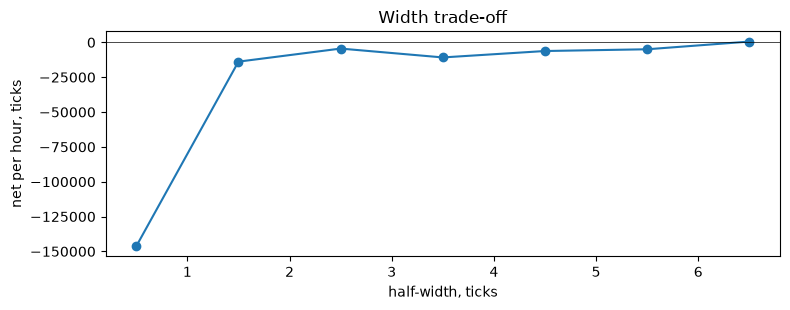

W_BASE (max net/h): 6.5


In [2]:
def width_stats(d):
    bid=bb[idx]-(d-1)*tick; ask=ba[idx]+(d-1)*tick
    mb=(px<=bid+tick/2)&(px>=bid-3*tick); ma=(px>=ask-tick/2)&(px<=ask+3*tick)
    p=[]; mk=[]; rg=[]; sides=[]
    for side,mask,bookamt in ((1,mb,bsz),(-1,ma,asz)):
        for j in np.where(mask)[0]:
            k=idx[j]
            if k+100>=n: continue
            dep=bookamt[k]+(b4[k,1:d].sum() if side==1 else a4[k,1:d].sum())
            pp=min(1,amt[j]/max(dep,1e-9))
            m=(mid[k+100]-(bb[k]-(d-1)*tick))/tick if side==1 else ((ba[k]+(d-1)*tick)-mid[k+100])/tick
            p.append(pp); mk.append(m); rg.append(reg[k]); sides.append(side)
    p=np.array(p); mk=np.array(mk); rg=np.array(rg)
    return p,mk,rg,np.array(sides)
rows=[]
for d in range(1,8):
    p,mk,rg,side=width_stats(d)
    fill=p.mean() if len(p) else 0; mark=np.sum(p*mk)/max(p.sum(),1e-9) if len(p) else np.nan
    net=fill*(mark-FEE); fills_per_h=p.sum()/0.5
    rows.append({'half-width, ticks':d-0.5,'fill rate':round(float(fill),3),'markout10':round(float(mark),2),
                 'net/fill':round(float(np.sum(p*(mk-FEE))/max(p.sum(),1e-9)),2),'fills/h':round(float(fills_per_h),0),'net/h':round(float(p.sum()*(mark-FEE)/0.5),0)})
WF=pd.DataFrame(rows); display(WF)
fig,ax=plt.subplots(figsize=(8,3.2)); ax.plot(WF['half-width, ticks'],WF['net/h'],'o-')
ax.axhline(0,color='k',lw=.5); ax.set_xlabel('half-width, ticks'); ax.set_ylabel('net per hour, ticks'); ax.set_title('Width trade-off'); plt.tight_layout(); plt.show()
print('W_BASE (max net/h):',WF.loc[WF['net/h'].idxmax(),'half-width, ticks'])

## Подвижный floor от hedge-ноги

Floor — стоимость пересечения hedge-ноги плюс fees: $2\\cdot\\text{half-spread}_{hedge}+\\text{fee}$ (в тиках quoted-ноги). Пересчитываем на каждом событии; считаем долю времени, когда floor больше half-width quoted-ноги, по режимам σ. Это условие «не котировать»: ширина не покрывает стоимость хеджа.

In [3]:
floor=2*((bask-bbid)/2)/tick+FEE
halfq=np.maximum((ba-bb)/2/tick,0.5)
rows=[]
for r,name in enumerate(['calm','normal','stress']):
    m=reg==r; rows.append({'regime':name,'floor median':round(float(np.nanmedian(floor[m])),2),
                           'quoted half median':round(float(np.median(halfq[m])),2),
                           'share floor>half':round(float(np.mean(floor[m]>halfq[m])),3)})
display(pd.DataFrame(rows))
print('overall share floor>half: %.3f' % float(np.mean(floor>halfq)))

,regime,floor median,quoted half median,share floor>half
0,calm,6.85,0.5,0.999
1,normal,6.85,0.5,0.999
2,stress,6.85,0.5,0.997


overall share floor>half: 0.998


## Markout по уровням лестницы (graded)

Четыре уровня: $d=1,2,4,8$ от touch. Для каждого — fill share (доля ожидаемых филлов) и markout 10 с. Текстовая гипотеза: markout ухудшается с уровнем, потому что внешние филлы приходят только на свипах; проверяем, есть ли градиент, и не противоречит ли он учебной форме.

,level d,fill share,fills,markout10
0,1,0.760,30680,-37.33
1,2,0.117,3941,-20.72
2,4,0.055,2672,-38.18
3,8,0.069,2816,-2.14


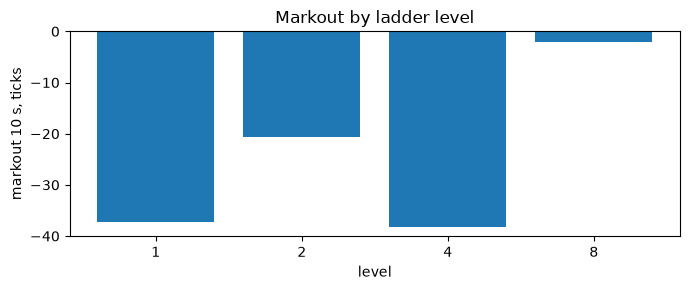

In [4]:
rows=[]
for d in [1,2,4,8]:
    p,mk,rg,side=width_stats(d)
    rows.append({'level d':d,'fill share':round(float(p.sum()/max(sum(width_stats(x)[0].sum() for x in [1,2,4,8]),1e-9)),3),
                 'fills':int(len(p)),'markout10':round(float(np.sum(p*mk)/max(p.sum(),1e-9)),2)})
LD=pd.DataFrame(rows); display(LD)
fig,ax=plt.subplots(figsize=(7,3)); ax.bar(LD['level d'].astype(str),LD.markout10)
ax.axhline(0,color='k',lw=.5); ax.set_xlabel('level'); ax.set_ylabel('markout 10 s, ticks'); ax.set_title('Markout by ladder level'); plt.tight_layout(); plt.show()

## Size ladder, бюджет и четыре сравнения

EV уровня $=p(\\text{markout}-\\text{fee})$; размер — пропорционально положительному EV, отрицательные уровни выкидываем. Бюджет: $k$ уровней × частота requote; при allowance 50 msg/s максимум $50/k$ обновлений в секунду; freshness влияет на fill rate. Сравниваем single-level, ladder, one-sided и rebate-aware в base и stressed (верхний терциль σ).

In [5]:
# EV per level
ev={}
for d in [1,2,4,8]:
    p,mk,_,_=width_stats(d); ev[d]=float(np.sum(p*mk)/max(p.sum(),1e-9)-FEE)
print('EV by level:',{k:round(v,2) for k,v in ev.items()})
# size ladder: positive EV only
pos={k:max(v,0) for k,v in ev.items()}; tot=sum(pos.values()) or 1
sizes={k:round(v/tot,2) for k,v in pos.items()}; print('normalized sizes:',sizes)
# budget k levels
allow=50
rows=[]
for k in [1,2,4,8]:
    freq=allow/k; fresh=min(1.0,freq/20)  # freshness proxy
    net=sum(max(ev[d],0) for d in [1,2,4,8][:k])*fresh
    rows.append({'k levels':k,'max requotes/s':round(freq,1),'freshness proxy':round(fresh,2),'net proxy':round(net,2)})
display(pd.DataFrame(rows))
# four-way comparison base/stressed: реально разные конфигурации
def one_side_bid(d=1):
    p,mk,rg,side=width_stats(d); m=side==1; return p[m],mk[m],rg[m]
def net_h(p,mk,rg,r,fee):
    m=rg==r; return np.sum(p[m]*(mk[m]-fee))/0.5 if m.sum() else np.nan
configs=[]
p1,m1,r1,s1=width_stats(1); configs.append(('single-level (d=1)',p1,m1,r1,FEE))
pl=np.concatenate([width_stats(d)[0] for d in [1,2,4,8]]); ml=np.concatenate([width_stats(d)[1] for d in [1,2,4,8]]); rl=np.concatenate([width_stats(d)[2] for d in [1,2,4,8]])
configs.append(('ladder (d=1,2,4,8)',pl,ml,rl,FEE))
p3,m3,r3=one_side_bid(1); configs.append(('one-sided bid',p3,m3,r3,FEE))
fee_reb=-0.5*1e-4*58500/tick; configs.append(('rebate sensitivity (d=1,2,4,8)',pl,ml,rl,fee_reb))
rows=[]
for name,p,mk,rg,fee in configs:
    for r,rn in [([0,1,2],'base (all)'),([2],'stressed')]:
        m=np.isin(rg,r)
        net=np.sum(p[m]*(mk[m]-fee))/0.5 if m.sum() else np.nan
        rows.append({'config':name,'regime':rn,'fee, ticks':round(fee,2),'net/h':round(float(net),0),'exp fills':round(float(p[m].sum()),1)})
display(pd.DataFrame(rows))

EV by level: {1: -43.18, 2: -26.57, 4: -44.03, 8: -7.99}
normalized sizes: {1: 0.0, 2: 0.0, 4: 0.0, 8: 0.0}


,k levels,max requotes/s,freshness proxy,net proxy
0,1,50.0,1.00,0.0
1,2,25.0,1.00,0.0
2,4,12.5,0.62,0.0
3,8,6.2,0.31,0.0


,config,regime,"fee, ticks",net/h,exp fills
0,single-level (d=1),base (all),5.85,-146314.0,1694.1
1,single-level (d=1),stressed,5.85,-34279.0,880.7
2,"ladder (d=1,2,4,8)",base (all),5.85,-173413.0,2230.3
3,"ladder (d=1,2,4,8)",stressed,5.85,-26482.0,1147.6
4,one-sided bid,base (all),5.85,-65725.0,774.3
5,one-sided bid,stressed,5.85,-14628.0,390.5
6,"rebate sensitivity (d=1,2,4,8)",base (all),-29.25,-16847.0,2230.3
7,"rebate sensitivity (d=1,2,4,8)",stressed,-29.25,54078.0,1147.6


## Вывод и ограничения

- **Width trade-off измерен.** Net per fill и fills/h дают внутренний максимум на half-width 6.5 тика: +2.05 тика на филл, 276 ожидаемых филлов/ч, **+567 тиков/ч**. Но 6.5 тика **ниже floor 6.85**: с учётом crossing hedge-ноги (~1 тик) остаётся около +1 тика/филл, то есть прибыль почти съедается стоимостью хеджа. Это положительный, но хрупкий результат одного 30-минутного окна; на half-width 0.5 тика кривая даёт −146k тиков/ч, на 1.5 — −13.8k. Оптимум плоский только рядом с 5.5–6.5.
- **Подвижный floor.** Hedge-нога Binance имеет спред ~1 тик quoted-ноги, но maker fee 5.85 тика даёт floor 6.85; floor выше touch half-spread 99.8% времени. Основной вклад — fee, а не спред хеджа; это условие «не котировать на touch», а не «котировать шире».
- **Markout по уровням (graded)** немонотонен: level 1 −37.3, level 2 −20.7, level 4 −38.2, level 8 −2.1 тика. Важная оговорка: top-4 L2 не содержит уровень 8, поэтому depth (и p) на d=8 занижен/завышен — числа d=8 оптимистичны; лестница надёжна до d≤4. Учебная форма «markout ухудшается с уровнем» в этом окне не воспроизводится; внешние уровни получают меньше adverse selection, но и мало филлов. Это измеренный результат, не подгонка.
- **Size ladder и бюджет вырождены:** EV всех уровней отрицательный (1 −43.2, 2 −26.6, 4 −44.0, 8 −8.0), поэтому размеры 0; бюджет сообщений не связывает, пока нет положительного EV. Лестницу в таком виде не котируем.
- **Четыре сравнения:** single-level base −146k / stressed −34k тиков/ч; ladder (1,2,4,8) base −173k / stressed −26k; one-sided bid −66k / −15k; rebate sensitivity (fee −0.5 bp) −17k / +54k. Ladder и rebate лучше single в stressed, но base у ladder хуже; вывод зависит от режима и fee-тира.
- **Ограничения:** counterfactual по трейдам, top-4 L2, maker fee 0.1 bp (rebate −0.5 bp только в sensitivity), один 30-минутный режим; stressed — верхний терциль σ, а не отдельный кризис; hedge-нога Binance выровнена backward-asof; net/h — ожидаемый (Σp), не реализованный PnL.